# Cohort construction: who joined when?

**Week 4, Thursday, SECTION 1, the first of five concept notebooks.** The gym, its thirty
members and their visits are invented for this chapter. Week 2 Thursday reshaped tables with
`melt` and `pivot_table`; this notebook uses both to fix the month each member joined and to
count every group at the same age. The case notebooks, 05 to 07, apply the same moves to
Zomato Gold.

**Who needs the answer.** The owner of a neighbourhood gym, who wants to know which month's
joiners keep coming, so that a retention offer reaches the batch that needs it. Read by
calendar month, the offer goes to the wrong batch.

**The questions on the way.**

1. Which batch looks best in April?
2. What does each batch keep at each age?
3. Why is the table a triangle?
4. How does code count the same table?

In [1]:
# Load the register: one row per member, one column per month, 1 if she visited, blank before she joined.
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = []
def check(name, ok):
    RESULTS.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

MONTHS = ["jan", "feb", "mar", "apr", "may", "jun"]
roster = pd.read_csv("../data/C2_W04_D04_toy_gym_roster_STUDENT.csv", dtype={m: "Int64" for m in MONTHS})
print("One branch's register, January to June 2026 (invented), in full:")
print(roster.astype(object).where(roster.notna(), "").to_string(index=False))

One branch's register, January to June 2026 (invented), in full:
member_id joined jan feb mar apr may jun
      G01    jan   1   1   1   1   1   1
      G02    jan   1   1   0   0   0   0
      G03    jan   1   1   1   1   1   1
      G04    jan   1   0   0   0   0   0
      G05    jan   1   1   1   0   0   0
      G06    jan   1   1   1   1   1   1
      G07    jan   1   1   1   1   1   1
      G08    jan   1   1   0   0   0   0
      G09    jan   1   0   0   0   0   0
      G10    jan   1   1   1   1   1   1
      G11    feb       1   1   1   1   1
      G12    feb       1   0   0   0   0
      G13    feb       1   1   1   0   0
      G14    feb       1   1   1   1   1
      G15    feb       1   1   0   0   0
      G16    feb       1   0   0   0   0
      G17    feb       1   1   1   1   1
      G18    feb       1   1   1   0   0
      G19    feb       1   0   0   0   0
      G20    feb       1   1   0   0   0
      G21    mar           1   1   1   1
      G22    mar           1   0 

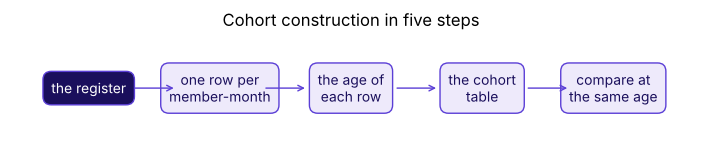

In [2]:
# The map: the chapter's steps in order; this notebook starts on the lit one and walks them all.
steps = ["the register", "one row per\nmember-month", "the age of\neach row", "the cohort\ntable", "compare at\nthe same age"]
fig, ax = plt.subplots(figsize=(8.8, 1.4))
for i, s in enumerate(steps):
    ax.text(i, 0, s, ha="center", va="center", fontsize=10, color="white" if i == 0 else "#1A0F5C",
            bbox=dict(boxstyle="round,pad=0.6", fc="#1A0F5C" if i == 0 else "#EEEAFB", ec="#5B3FD6"))
for i in range(1, len(steps)):
    ax.annotate("", xy=(i - 0.33, 0), xytext=(i - 0.67, 0), arrowprops=dict(arrowstyle="->", color="#5B3FD6"))
ax.set_xlim(-0.6, len(steps) - 0.4); ax.set_ylim(-0.7, 0.7); ax.axis("off")
ax.set_title("Cohort construction in five steps"); plt.show()

## Which batch looks best in April?

In April the owner reads the register's April row: 5 of the 10 January joiners visited, 5 of
the 10 February joiners and 6 of the 10 March joiners, so the owner calls March the best
batch. **Month one** is the first full calendar month after joining. The joining month is
**month zero** and is never counted, since everyone visits the month they join. **Predict before
you run.** Counted by months since joining, which batch keeps the most in its own month one?

- a) March, as the owner reads it
- b) February
- c) January
- d) All three keep the same share

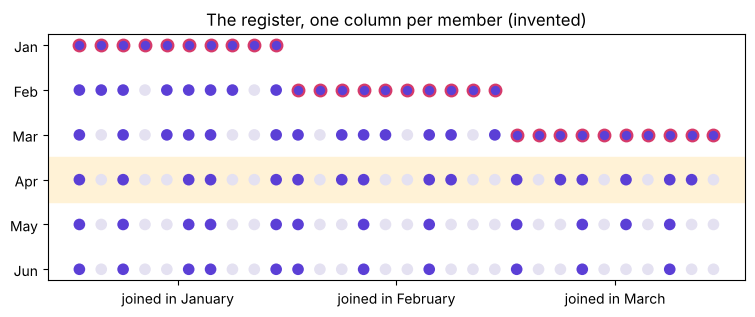

        visited  members
joined                  
jan           5       10
feb           5       10
mar           6       10
PASS  April's row reads 5, 5 and 6 of 10, 16 of 30 in all


In [3]:
# The register drawn: dark visited, light did not, ringed the joining month; April, the owner's row, shaded.
fig, ax = plt.subplots(figsize=(9.0, 3.2))
for x, (_, r) in enumerate(roster.iterrows()):
    for y, m in enumerate(MONTHS):
        if pd.notna(r[m]):
            ax.scatter(x, y, s=70, c="#5B3FD6" if r[m] == 1 else "#E4E1F1",
                       edgecolors="#D63A6A" if m == r["joined"] else "none", linewidths=1.6)
ax.axhspan(2.5, 3.5, color="#FFF2D6", zorder=0)
ax.set_yticks(range(6), ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]); ax.invert_yaxis()
ax.set_xticks([4.5, 14.5, 24.5], ["joined in January", "joined in February", "joined in March"])
ax.set_title("The register, one column per member (invented)"); plt.show()
april = roster.groupby("joined", sort=False)["apr"].agg(visited="sum", members="count")
print(april)
check("April's row reads 5, 5 and 6 of 10, 16 of 30 in all",
      list(april["visited"]) == [5, 5, 6] and (april["visited"].sum(), april["members"].sum()) == (16, 30))

## What does each batch keep at each age?

Count by hand before any code. A member's **age** in a month is how many months after her
joining month it is, so a January joiner is at age one in February, and a March joiner is at
age one in April. January's ten joiners are G01 to G10 in the printed register: down the `feb`
column for those ten rows, 8 read 1; down `mar`, 6; down `apr`, `may` and `jun`, 5 each.
February's ten, G11 to G20, start in `mar`, and March's ten, G21 to G30, start in `apr`. The
next cell holds the hand count as numbers, counts the same table in code, and checks that the
two agree.

In [4]:
# The hand count, typed in; the same count in code; and the check that the two agree.
by_hand = {"jan": [8, 6, 5, 5, 5], "feb": [7, 5, 3, 3], "mar": [6, 4, 3]}
PLACE = {"jan": 0, "feb": 1, "mar": 2, "apr": 3, "may": 4, "jun": 5}
long = roster.melt(id_vars=["member_id", "joined"], var_name="month",
                   value_name="visited").dropna()                 # one row per member per month
long["visited"] = long["visited"].astype(int)
long["age"] = long["month"].map(PLACE) - long["joined"].map(PLACE)  # joining month = age 0
counted = long[long["age"] >= 1].pivot_table(index="joined", columns="age", values="visited",
                                             aggfunc=["sum", "count"], sort=False)
by_code = {c: [int(v) for v in row.dropna()] for c, row in counted["sum"].iterrows()}
print(counted["sum"].astype("Int64"))
check("the code's counts equal the hand count, batch by batch", by_code == by_hand)
check("every cell divides by the whole batch of 10", set(counted["count"].stack().dropna()) == {10})

age     1  2  3     4     5
joined                     
jan     8  6  5     5     5
feb     7  5  3     3  <NA>
mar     6  4  3  <NA>  <NA>
PASS  the code's counts equal the hand count, batch by batch
PASS  every cell divides by the whole batch of 10


**What happened.** The answer is c. At age one the batches keep 8, 7 and 6 of 10: January 80
percent, February 70 and March 60. March, best in April, is the weakest at the same age, because
April's row mixed January at age three, February at age two and March at age one, and its 16 of
30 names no batch.

## Why is the table a triangle?

Each row is a **cohort**, everyone who joined in the same month, and each column is an age. By
June, March's joiners have lived only three ages, so their row is short, and a newer cohort's
row is always shorter: that is why a cohort table is a triangle. **Named last, the formula:**
retention of cohort c at age k = members of c who visited at age k ÷ the members of c. January
at age two: 6 ÷ 10 = 60 percent. The next cell computes the shares with the same `pivot_table`
and `aggfunc="mean"`: each cell is the mean of ones and zeros, which is the share who visited.

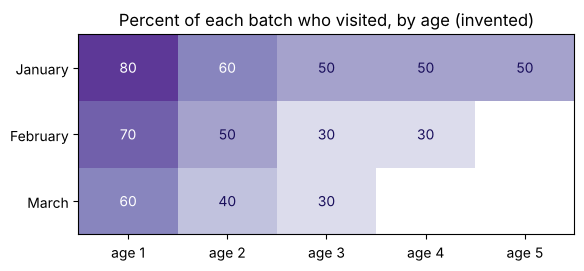

PASS  January's row reads 0.8, 0.6, 0.5, 0.5, 0.5
PASS  no batch's row rises with age


age,1,2,3,4,5
joined,,,,,
jan,80.0,60.0,50.0,50.0,50.0
feb,70.0,50.0,30.0,30.0,NaN
mar,60.0,40.0,30.0,NaN,NaN


In [5]:
# The cohort table as shares, drawn as a triangle: rows by joining month, columns by age.
tri = long[long["age"] >= 1].pivot_table(index="joined", columns="age", values="visited",
                                         aggfunc="mean", sort=False)
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.imshow(tri.values, cmap="Purples", vmin=0.1, vmax=0.95, aspect="auto")
for (c, a), v in tri.stack().dropna().items():
    ax.text(a - 1, list(tri.index).index(c), f"{100 * v:.0f}", ha="center", va="center",
            color="white" if v >= 0.6 else "#1A0F5C")
ax.set_xticks(range(tri.shape[1]), [f"age {a}" for a in tri.columns])
ax.set_yticks(range(3), ["January", "February", "March"])
ax.set_title("Percent of each batch who visited, by age (invented)"); plt.show()
check("January's row reads 0.8, 0.6, 0.5, 0.5, 0.5", [round(v, 2) for v in tri.loc["jan"]] == [0.8, 0.6, 0.5, 0.5, 0.5])
check("no batch's row rises with age", all((row.dropna().diff().dropna() <= 0).all() for _, row in tri.iterrows()))
(100 * tri).round(0)

**The plausible wrong answer.** "March is our best batch: 6 of 10 came in April." The decision
it would mislead: the retention offer goes to the January and February joiners, while the batch
that keeps the least at the same age gets nothing. **Why it is wrong.** One calendar month holds
three ages at once. **The check** is the same-age column: at age one, March is last.

**The rule as a function, and a second route.** The next cell wraps the count in `cohort_table`,
then recounts January's row with a plain loop over its ten members and no `pivot_table`; the two
must agree before the table is trusted. It ends by drawing the two readings side by side.

PASS  a loop over January's ten members gives the function's row


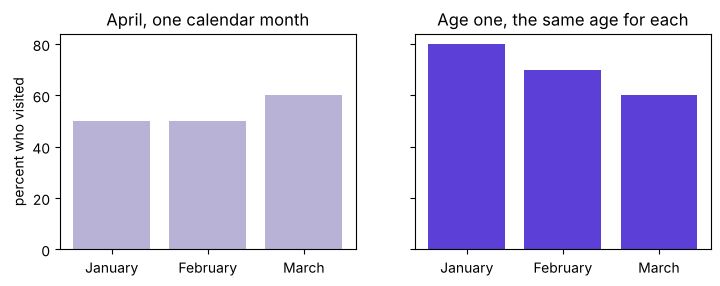

In [6]:
# The rule as a function; January's row recounted by a loop; the two readings side by side.
def cohort_table(register):
    """Share of each joining month's members who visited at each age; age zero left out."""
    rows = register.melt(id_vars=["member_id", "joined"], var_name="month", value_name="visited").dropna()
    rows["visited"] = rows["visited"].astype(int)
    rows["age"] = rows["month"].map(PLACE) - rows["joined"].map(PLACE)
    return rows[rows["age"] >= 1].pivot_table(index="joined", columns="age", values="visited",
                                              aggfunc="mean", sort=False)

jan = roster[roster["joined"] == "jan"]
loop = [sum(1 for v in jan[m] if v == 1) / len(jan) for m in MONTHS[1:]]
check("a loop over January's ten members gives the function's row",
      [round(v, 9) for v in loop] == [round(v, 9) for v in cohort_table(roster).loc["jan"]])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.4, 2.8), sharey=True)
names = ["January", "February", "March"]
a1.bar(names, 100 * april["visited"].astype(int).values / 10, color="#B8B2D6")
a1.set_title("April, one calendar month")
a2.bar(names, 100 * tri[1].values, color="#5B3FD6"); a2.set_title("Age one, the same age for each")
a1.set_ylabel("percent who visited"); plt.show()

## Your turn: what does May's row say, read both ways?

In May the owner reads the register again. **Your turn.** In the empty cell, count May's row by
joining month, give each count its age, and say which batch a calendar reading of May ranks
above which, and whether the same-age table agrees. Two lines to start from:

```python
roster.groupby("joined", sort=False)["may"].sum()
{j: PLACE["may"] - PLACE[j] for j in ["jan", "feb", "mar"]}
```

**Check your cell against this one.** It prints May's row by joining month with the age of each
count, then counts every check this notebook has run.

In [7]:
# May's row by joining month, each count with its age; then every check in this notebook counted.
may = roster.groupby("joined", sort=False)["may"].sum().astype(int)
age_in_may = pd.Series({j: PLACE["may"] - PLACE[j] for j in may.index})
print(pd.DataFrame({"visited in May, of 10": may, "age in May": age_in_may}))
check("May's row reads 5, 3 and 4 of 10, at ages 4, 3 and 2",
      list(may) == [5, 3, 4] and list(age_in_may) == [4, 3, 2])
print(f"{sum(RESULTS)} of {len(RESULTS)} checks pass")

     visited in May, of 10  age in May
jan                      5           4
feb                      3           3
mar                      4           2
PASS  May's row reads 5, 3 and 4 of 10, at ages 4, 3 and 2
7 of 7 checks pass


## What does an analyst do every time a cohort table is built?

1. A cohort is everyone who joined in the same month, and a member keeps her cohort for good.
2. The joining month is age zero and is never counted; age one is the first full month after it.
3. Every cell divides by the whole cohort, never by the members who visited the month before.
4. Cohorts are compared at the same age, since one calendar month mixes ages and names no cohort.

May's row says it again: read by calendar month it ranks March above February, 4 of 10 against
3, while at the same age February keeps more, 7 against 6 at age one and 5 against 4 at age two.

**In the interview.** [S] "Retention dropped; walk me through your investigation." The first
move a strong candidate makes: "I'd fix each member's joining month and compare cohorts at the
same age before I read any blended number."

**What comes next.** Notebook 02 reads each row of this table as a curve and finds where it
stops falling. Notebook 05 counts twelve Zomato Gold members the same way, by hand and then in
code.